In [1]:
### follow the notebook for potential profile color map for harmonic oscillator confinement potential and charge trap 

In [13]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
#from Minimal_Model_2D import *
from Minimal_Model_2D import *
import time

np.set_printoptions(threshold=sys.maxsize)

In [14]:
class Minimal_Model_confinement_and_charge_trap_potential(twoD_Minimal_Model):

    ### method to plot potential 

    def pot(self, x_ct= 0, y_ct=0, z_ct=50, z_im=50.2, z_qw=0, f_ct =0, a_ct=1 ):

        return a_ct*1/4/hbm*self.meff_sm*self.omega**2*self.twodOP.ysq() + f_ct*self.charge_pot_lattice(x_ct, y_ct, z_ct, z_im, z_qw)


In [15]:

NSM = 60            # number of sm x lattice points
M = 60              # should be atleast thrice confinement length
AX = 5              # lattice spacing in nm
AY = 5              # lattice spacing in nm
DELTA = 0.165       # in meV
MEFF_SC = 0.023     # proximitized InAs
MEFF_SM = 0.023     # InAs
NSC = 800
NTOT = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT = 400        # meV-nm^3 # 20 is within perturbative regime for widths atleast up to 100 nm
K_NUM = 4           # No of eigenvalues needed to be found 
#W_MIN = 50

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

MY= 5 

print('lengths=', M*AY, LY)
OMEGA = 2*4*hbm/LY**2/MEFF_SC


print('subband energies=', OMEGA/2, 3*OMEGA/2)

print('4t=', 4*hbm/AX**2/MEFF_SC)

MU_SC =   OMEGA/2 +OMEGA/10  # in between two subbands - such that we get two abs prferably 
MU_SM =   OMEGA/2 +OMEGA/10  # in between two subbands - such that we get two abs prferably

print('mu = ', MU_SM)


UNCORR_VAR = 1167  ### uncorrelated variance of disorder
LMBDA = np.linspace(0.00, 0.21, 51)
SEED = 58  ## seed for the disorder


Mod = Minimal_Model_confinement_and_charge_trap_potential(NTOT,NSM,NSC,M,AX,AY,OMEGA, delta=DELTA, meff_sc=MEFF_SC, meff_sm=MEFF_SM, mu_sm = MU_SM, mu_sc=MU_SC)
#print(Mod.charge_trap_pot(x_ct=(NSC)*AX), 'in meV')


lengths= 300 100
subband energies= 0.6631720133634798 1.9895160400904393
4t= 265.2688053453919
mu =  0.7958064160361757


In [16]:
#XCT = (NSC+NSM/2)*AX
#YCT = M/2*AY

XCT = (NSC+NSM/2)*AX
YCT = M/2*AY
FCT=1
ACT=0

K = Mod.pot(x_ct=XCT, y_ct=YCT, f_ct=FCT, a_ct=ACT).toarray().diagonal()
J = K.reshape(M,NTOT)


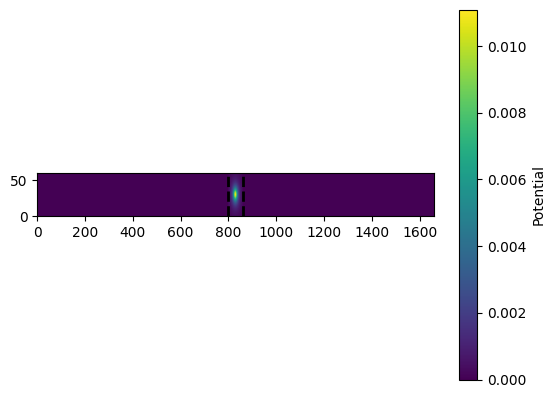

In [20]:
# plot the potential due to image charge
#f = plt.figure(figsize=(10, 8))
#plt.use('Agg')
# Set global figure size
#plt.rcParams['figure.figsize'] = [10, 8]
#fig = plt.figure(figsize=(5, 5))
fig = plt.figure()
ax = fig.add_subplot(111)
#plt.close('all')
#%matplotlib inline

# Adjust extent to ensure the image fills the box completely
#ex = [0, J.shape[1], 0, J.shape[0]]

#fig, ax = plt.subplots(figsize=(10, 8))
cax = ax.imshow(J, aspect='auto', origin='lower', extent=ex)

# Reverse the y-axis
#ax.invert_yaxis()

# Add a colorbar to show the scale of potential
#fig.colorbar()

# Plot two vertical lines
#ax.axvline(x=(NSC-1), color='black', linestyle='--', linewidth=2)  # First vertical line at x=2
#ax.axvline(x=(NSM+NSC-1), color='black', linestyle='--', linewidth=2)  # Second vertical line at x=7

ax.axvline(x=(NSC), color='black', linestyle='--', linewidth=2)  # First vertical line at x=2
ax.axvline(x=(NSM+NSC), color='black', linestyle='--', linewidth=2)  # Second vertical line at x=7


# Add a colorbar to show the scale of potential
cbar = fig.colorbar(cax, ax=ax)
cbar.set_label('Potential')
ax.set_aspect(3.0)

# Display the plot
plt.show()

# Save the plot to a file to check the size
fig.savefig('output.png', bbox_inches='tight')


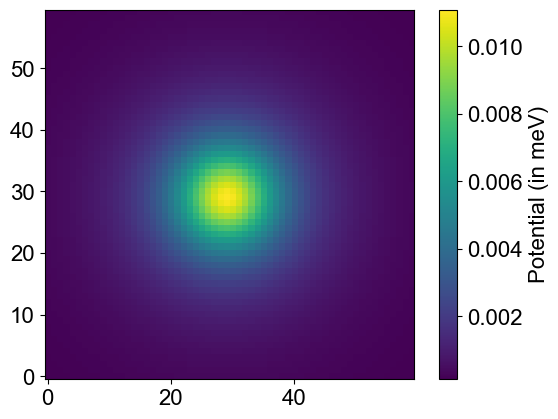

In [40]:
#XCT = (NSC+NSM/2)*AX
#YCT = M/2*AY

XCT = (NSC+NSM/2)*AX
YCT = M/2*AY
FCT=1
ACT=0

K = Mod.pot(x_ct=XCT, y_ct=YCT, f_ct=FCT, a_ct=ACT).toarray().diagonal()
J = K.reshape(M,NTOT)

# plot the potential due to image charge
#f = plt.figure(figsize=(10, 8))
#plt.use('Agg')
# Set global figure size
#plt.rcParams['figure.figsize'] = [10, 8]
#fig = plt.figure(figsize=(5, 5))

# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'
plt.rc('font', size=16)

fig = plt.figure()
ax = fig.add_subplot(111)
#plt.close('all')
#%matplotlib inline

# Adjust extent to ensure the image fills the box completely
#ex = [0, J.shape[1], 0, J.shape[0]]

#fig, ax = plt.subplots(figsize=(10, 8))
cax = ax.imshow(J[:, NSC:NSC+NSM], aspect='auto', origin='lower')
#cax = ax.imshow(J, aspect='auto', origin='lower', extent=ex)

# Reverse the y-axis
#ax.invert_yaxis()

# Add a colorbar to show the scale of potential
#fig.colorbar()

# Plot two vertical lines
#ax.axvline(x=(NSC-1), color='black', linestyle='--', linewidth=2)  # First vertical line at x=2
#ax.axvline(x=(NSM+NSC-1), color='black', linestyle='--', linewidth=2)  # Second vertical line at x=7

#ax.axvline(x=(NSC), color='black', linestyle='--', linewidth=2)  # First vertical line at x=2
#ax.axvline(x=(NSM+NSC), color='black', linestyle='--', linewidth=2)  # Second vertical line at x=7


# Add a colorbar to show the scale of potential
cbar = fig.colorbar(cax, ax=ax)
cbar.set_label('Potential (in meV)')
ax.set_aspect(1.0)

# Display the plot
plt.show()

# Save the plot to a file to check the size
fig.savefig('output.png', bbox_inches='tight')


In [33]:
MATRIX = J[:, NSC:NSC+NSM]
print(MATRIX.shape)

(60, 60)


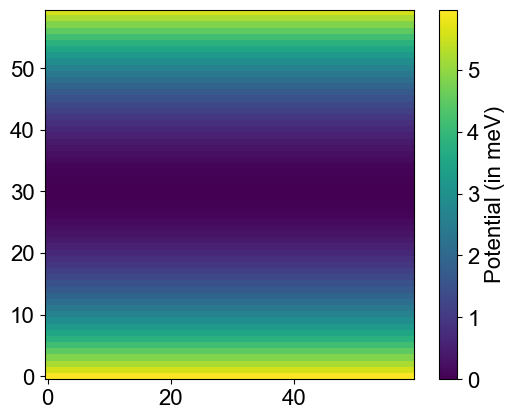

In [39]:
#XCT = (NSC+NSM/2)*AX
#YCT = M/2*AY

XCT = (NSC+NSM/2)*AX
YCT = M/2*AY
FCT=0
ACT=1

K = Mod.pot(x_ct=XCT, y_ct=YCT, f_ct=FCT, a_ct=ACT).toarray().diagonal()
J = K.reshape(M,NTOT)

# plot the potential due to image charge
#f = plt.figure(figsize=(10, 8))
#plt.use('Agg')
# Set global figure size
#plt.rcParams['figure.figsize'] = [10, 8]
#fig = plt.figure(figsize=(5, 5))

# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'
plt.rc('font', size=16)

fig = plt.figure()
ax = fig.add_subplot(111)
#plt.close('all')
#%matplotlib inline

# Adjust extent to ensure the image fills the box completely
#ex = [0, J.shape[1], 0, J.shape[0]]

#fig, ax = plt.subplots(figsize=(10, 8))
cax = ax.imshow(J[:, NSC:NSC+NSM], aspect='auto', origin='lower')
#cax = ax.imshow(J, aspect='auto', origin='lower', extent=ex)

# Reverse the y-axis
#ax.invert_yaxis()

# Add a colorbar to show the scale of potential
#fig.colorbar()

# Plot two vertical lines
#ax.axvline(x=(NSC-1), color='black', linestyle='--', linewidth=2)  # First vertical line at x=2
#ax.axvline(x=(NSM+NSC-1), color='black', linestyle='--', linewidth=2)  # Second vertical line at x=7

#ax.axvline(x=(NSC), color='black', linestyle='--', linewidth=2)  # First vertical line at x=2
#ax.axvline(x=(NSM+NSC), color='black', linestyle='--', linewidth=2)  # Second vertical line at x=7


# Add a colorbar to show the scale of potential
cbar = fig.colorbar(cax, ax=ax)
cbar.set_label('Potential (in meV)')
ax.set_aspect(1.0)

# Display the plot
plt.show()

# Save the plot to a file to check the size
fig.savefig('output.png', bbox_inches='tight')

